In [138]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
DATA_FULL = r"./_processed_profiles/stitched_profiles.csv"
df = pd.read_csv(DATA_FULL)

In [139]:
y = -df.loc[df["segment_id"] == 1]["node_gpu_power_W"]
p_bat_init = y[0]
y = y[1:]
x = np.diff(df.loc[df["segment_id"] == 1]["time_s"])

In [140]:
from simses.battery import Battery
from simses.converter.converter import Converter
from simses.model.cell.skeleton_SCA import SCA3200
from simses.model.cell.sony_lfp import SonyLFP
from simses.model.converter.fix_efficiency import FixedEfficiency
from simses.model.converter.sinamics import SinamicsS120Fit

from hess import HybridController


In [141]:
def build_controller(
        tau: float,
        bat_series: int = 16,
        bat_parallel: int = 20,
        sc_series: int = 22,
        sc_parallel: int = 3
        ):
    sc = Battery(
        cell=SCA3200(),
        circuit=(sc_series, sc_parallel),
        initial_states={
            "start_soc": 0.6,
            "start_T": 25.0,
        },
    )

    battery = Battery(
        cell=SonyLFP(),
        circuit=(bat_series, bat_parallel),
        initial_states={
            "start_soc": 0.6,
            "start_T": 25.0,
        },
    )
    supercap_converter = Converter(
        loss_model=FixedEfficiency(1.0),
        max_power=20e3,
        storage=sc,
    )

    battery_converter = Converter(
        loss_model=FixedEfficiency(1.0),
        max_power=20e3,
        storage=battery,
    )

    return HybridController(battery_converter, supercap_converter, tau)

1. P_req aus power profile
2. Abgleich mit Convertern ratings (ggf. anfallende mismatches schon hier loggen)
3. Logik, um split aus P_bat und P_sc zu bestimmen, wobei der SC die high freq power spikes abfangen sollte
4. SC wird gestepped, P_sc_actual wird aus sc.state.power ausgelesen
5. Battery wird um P_bat + dem delta aus P_sc und P_sc_ac gestepped
6. Jegliche over oder underflows werden gelogged

In [ ]:
taus = [0.1, 2, 5, 10, 25, 100]

bat_series = [14, 16, 18]
bat_parallel = [4, 6, 8]

sc_series = [20, 24, 28]
sc_parallel = [1, 2, 3]

logs = {
    tau : None for tau in taus
}

for tau in taus:
    hc = build_controller(tau)

    for time, power in zip(x,y):
        hc.step(power, time)
    
    logs[tau] = pd.DataFrame(hc.log)

# logs = {
#     "tau" : None,
#     "bat_s": None,
#     "bat_p": None,
#     "sc_s" : None,
#     "sc_p" : None,
#     "results":None
# }

# for tau, bs, bp, ss, sp in product(
#     taus, bat_series, bat_parallel, sc_series, sc_parallel
# ):
#     hc = build_controller(tau, bs, bp, ss, sp)

#     for time, power in zip(x,y):
#         hc.step(power, time)

#     logs["tau"] = tau,
#     logs["bat_s"] = bs,
#     logs["bat_p"] = bp
#     logs["sc_s"] = ss
#     logs["sc_p"] = sp
#     logs["results"] = pd.DataFrame(hc.log)

In [143]:
[logs[tau]["loss_fraction"].iloc[-1] for tau in taus]

KeyError: 0.1

In [ ]:
[logs[tau]["error_fraction"].iloc[-1] for tau in taus]

[np.float64(0.0),
 np.float64(5.1219048535622366e-20),
 np.float64(1.0243809707124473e-19),
 np.float64(2.0487619414248946e-19),
 np.float64(6.146285824274673e-19),
 np.float64(2.8170476694592474e-18)]

0.5617361254724548
0.5664151068709057
0.03520906170359577
2.0487619414248946e-19


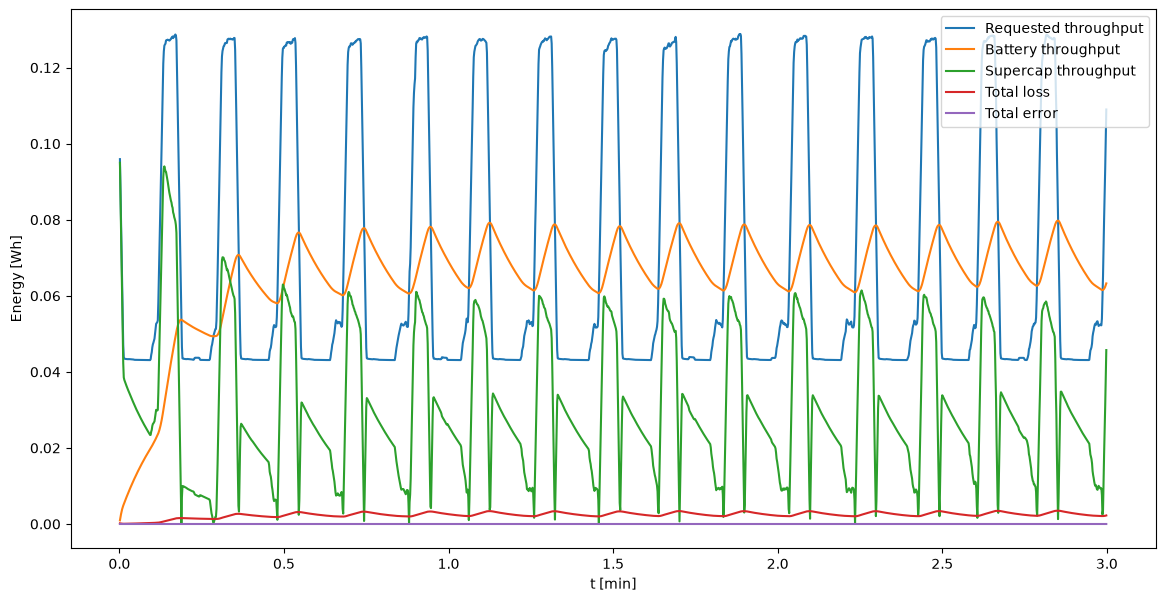

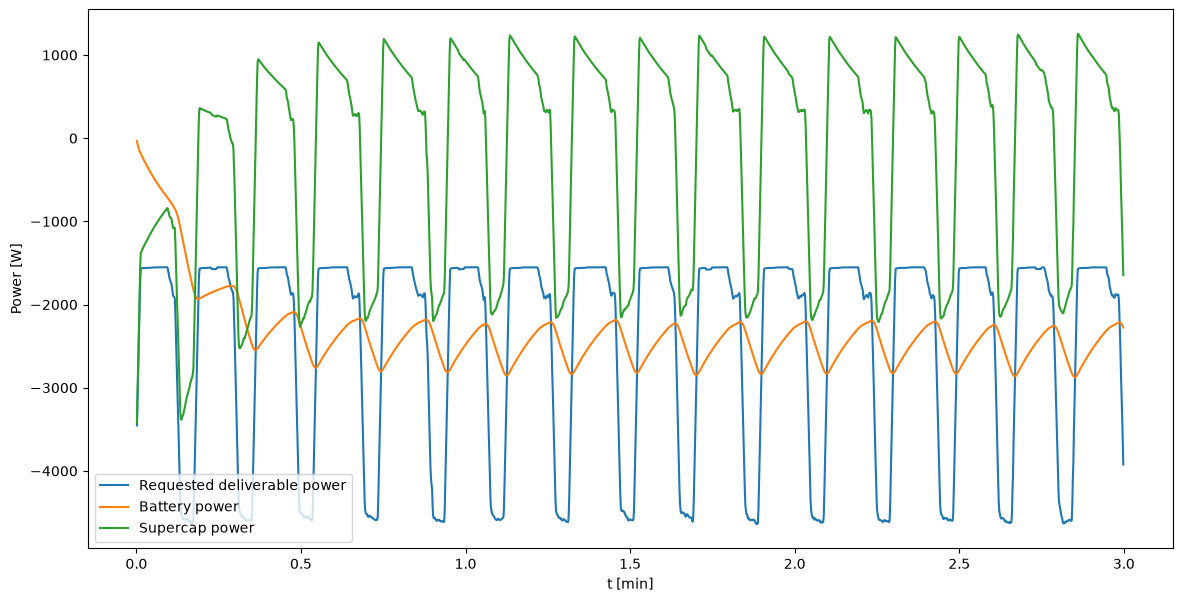

In [ ]:
i = 10

x_axis = df.loc[df["segment_id"] == 1]["time_s"][1:]/60

plt.figure(figsize=(14,7))
plt.plot(
    x_axis,
    logs[i]["dE_total_thr"],
    label="Requested throughput"
)
plt.plot(
    x_axis,
    logs[i]["dE_bat_thr"],
    label="Battery throughput"
)
plt.plot(
    x_axis,
    logs[i]["dE_sc_thr"],
    label="Supercap throughput"
)
plt.plot(
    x_axis,
    logs[i]["dE_total_loss"],
    label="Total loss"
)
plt.plot(
    x_axis,
    logs[i]["dE_total_error"],
    label="Total error"
)
plt.xlabel("t [min]")
plt.ylabel("Energy [Wh]")

plt.legend()

plt.figure(figsize=(14,7))
plt.plot(
    x_axis,
    logs[i]["p_total_actual"],
    label="Requested deliverable power"
)
plt.plot(
    x_axis,
    logs[i]["p_bat_actual"],
    label="Battery power"
)
plt.plot(
    x_axis,
    logs[i]["p_sc_actual"],
    label="Supercap power"
)
plt.xlabel("t [min]")
plt.ylabel("Power [W]")

plt.legend()

print(logs[i]["bat_soc"].iloc[-1])
print(logs[i]["sc_soc"].iloc[-1])
print(logs[i]["loss_fraction"].iloc[-1])
print(logs[i]["error_fraction"].iloc[-1])